На линкот е дадено податочно множество со карактерстики за личности и нивната преференца за одмор (1 означува „одмор на планина“, а 0 означува „одмор на плажа“).

- Најнапред, направете Exploratory Data Analysis (EDA) врз податочното множество.
- Потоа, соодветно претпроцесирајте ги податоците.
- На крај, тренирајте и евалуирајте модел по избор за предвидување на преференците врз основа на карактеристиките за личноста.

1. EXPLORATORY DATA ANALYSIS (EDA)
Основни информации:
Димензии: (52444, 14)
Колони: ['Age', 'Gender', 'Income', 'Education_Level', 'Travel_Frequency', 'Preferred_Activities', 'Vacation_Budget', 'Location', 'Proximity_to_Mountains', 'Proximity_to_Beaches', 'Favorite_Season', 'Pets', 'Environmental_Concerns', 'Preference']

Први 5 редови:
    Age      Gender  Income Education_Level  Travel_Frequency  \
0  56.0        male   71477        bachelor                 9   
1  69.0        male   88740          master                 1   
2  46.0      female   46562          master                 0   
3  32.0  non-binary   99044     high school                 6   
4  60.0      female  106583     high school                 5   

  Preferred_Activities  Vacation_Budget  Location  Proximity_to_Mountains  \
0               skiing             2477     urban                   175.0   
1             swimming             4777  suburban                     NaN   
2               skiing             146

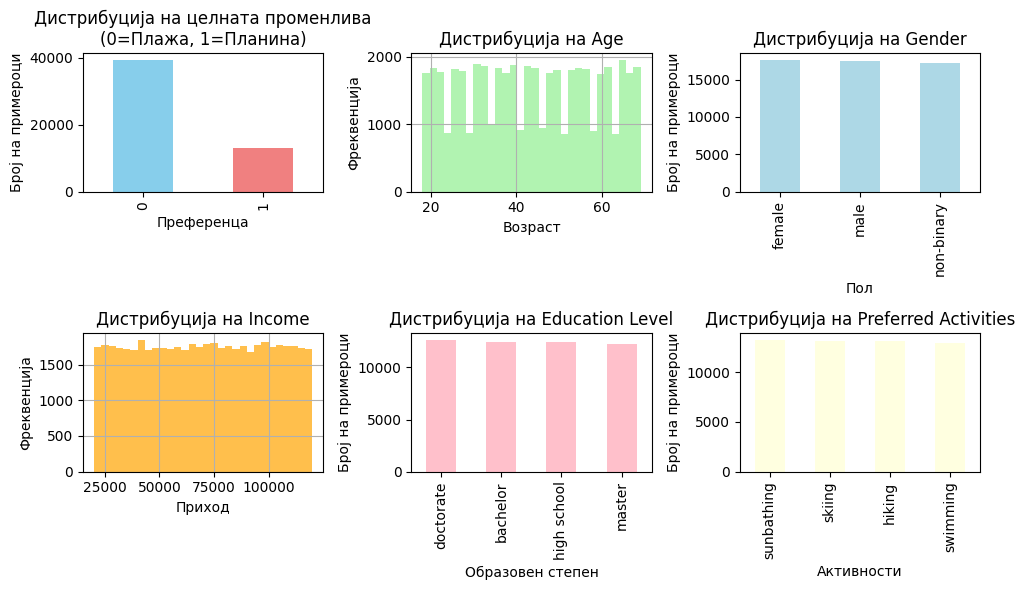

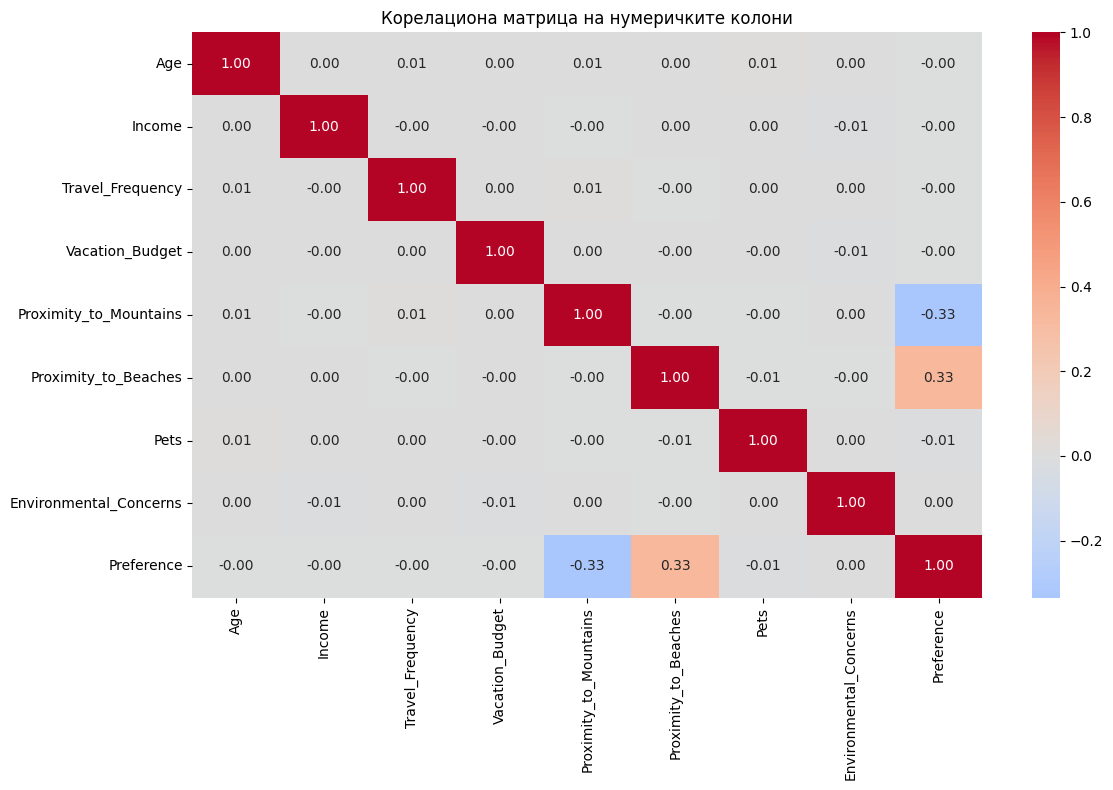

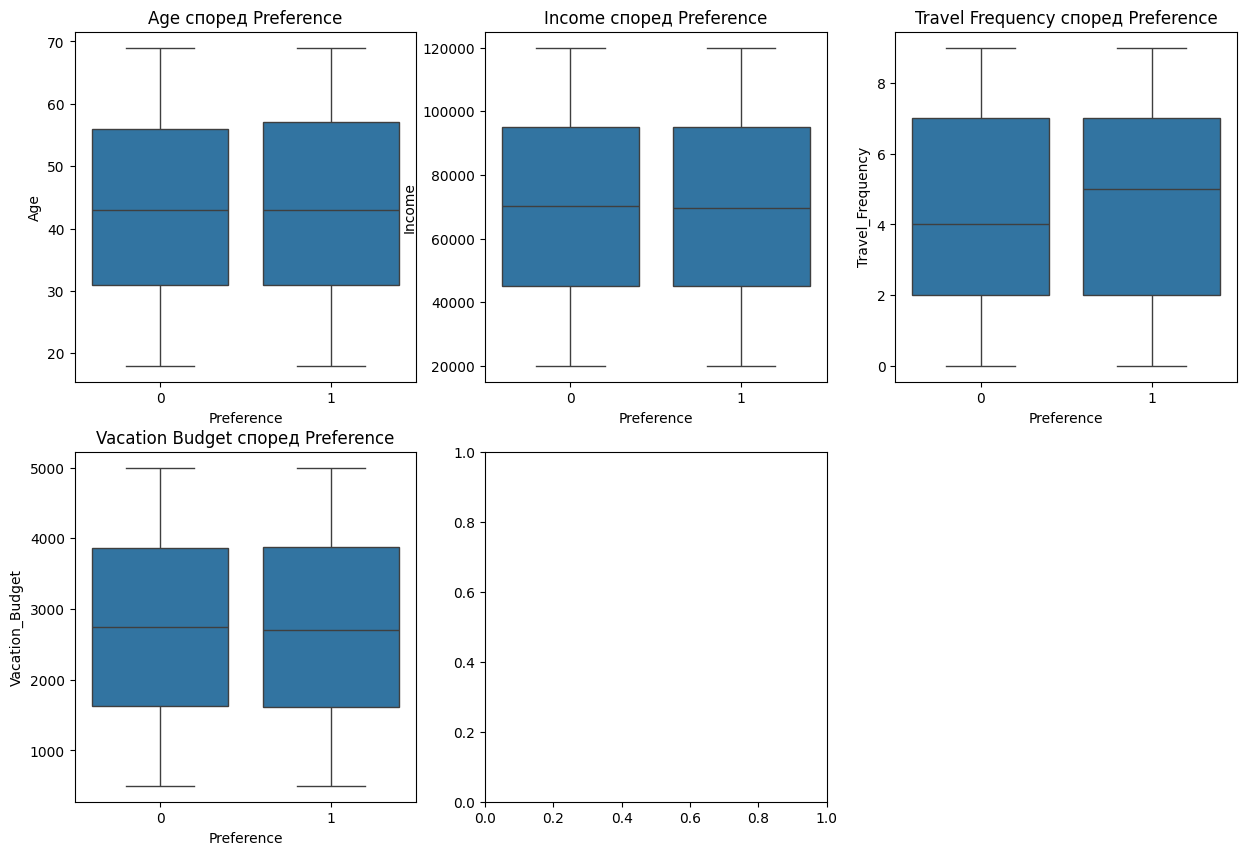

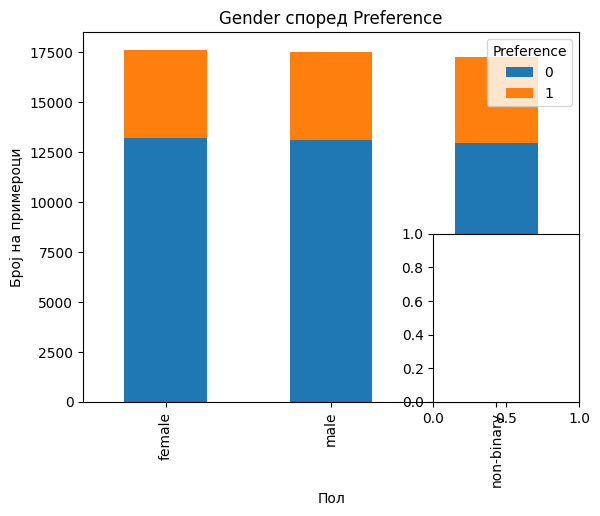

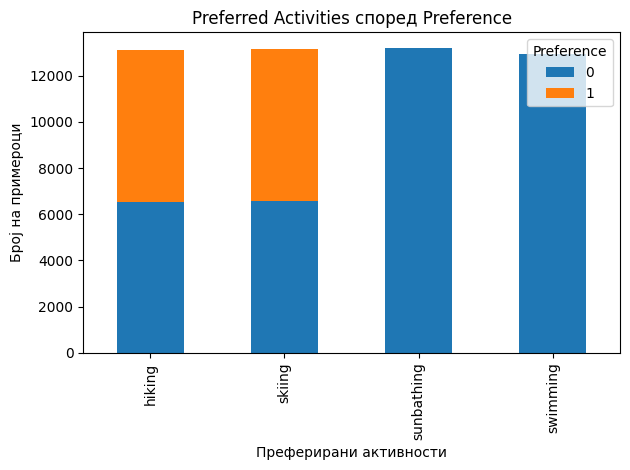


2. ПРЕТПРОЦЕСИРАЊЕ НА ПОДАТОЦИТЕ
Пополнување на недостасувачки вредности...
Кодирање на категоричките променливи...
Gender: {'female': 0, 'male': 1, 'non-binary': 2}
Education_Level: {'bachelor': 0, 'doctorate': 1, 'high school': 2, 'master': 3}
Preferred_Activities: {'hiking': 0, 'skiing': 1, 'sunbathing': 2, 'swimming': 3}
Location: {'rural': 0, 'suburban': 1, 'urban': 2}
Favorite_Season: {'fall': 0, 'spring': 1, 'summer': 2, 'winter': 3}

Димензии по претпроцесирање: (52444, 14)
Колони по претпроцесирање: ['Age', 'Gender', 'Income', 'Education_Level', 'Travel_Frequency', 'Preferred_Activities', 'Vacation_Budget', 'Location', 'Proximity_to_Mountains', 'Proximity_to_Beaches', 'Favorite_Season', 'Pets', 'Environmental_Concerns', 'Preference']

Недостасувачки вредности по претпроцесирање: 0

3. ТРЕНИРАЊЕ И ЕВАЛУАЦИЈА НА МОДЕЛ
Големина на тренирачко множество: (41955, 13)
Големина на тест множество: (10489, 13)
Дистрибуција на целната променлива во тренирачкото множество:
Preference
0  

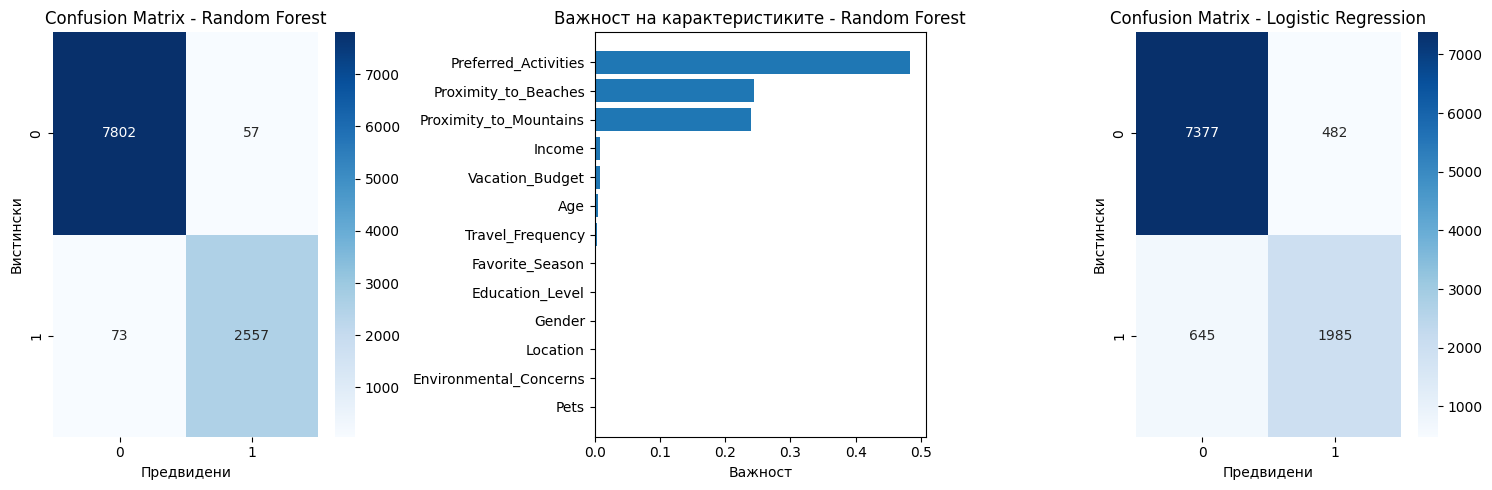


СПОРЕДБА НА МОДЕЛИТЕ
Random Forest Accuracy: 0.9876
Logistic Regression Accuracy: 0.8926

Примероци каде што моделите се разликуваат:
    Actual  RF_Predicted  RF_Probability  LR_Predicted
30       0             0        0.033476             1
35       0             0        0.447870             1
40       0             0        0.296595             1
50       1             1        0.694994             0
55       0             0        0.444832             1
69       1             1        0.833234             0
70       1             1        0.544025             0
73       1             1        0.813516             0
75       1             1        0.690256             0
89       0             0        0.490100             1

Анализа на грешките за Random Forest:
Лажни позитиви (предвиделе планина, а била плажа): 57
Лажни негативи (предвиделе плажа, а била планина): 73

ЗАКЛУЧОЦИ
1. Податочното множество има добар баланс помеѓу двете класи
2. Random Forest моделот покажува подобри

In [50]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score
from sklearn.impute import SimpleImputer

# 1. EXPLORATORY DATA ANALYSIS (EDA)
print("=" * 50)
print("1. EXPLORATORY DATA ANALYSIS (EDA)")
print("=" * 50)

# Вчитување на податоците
df = pd.read_csv('vacation_preferences_data.csv')

# Основни информации за податочното множество
print("Основни информации:")
print(f"Димензии: {df.shape}")
print(f"Колони: {df.columns.tolist()}")
print("\nПрви 5 редови:")
print(df.head())

print("\nИнформации за типовите на податоци и недостасувачки вредности:")
print(df.info())

print("\nСтатистички преглед на нумеричките колони:")
print(df.describe())

print("\nСтатистички преглед на категоричките колони:")
print(df.describe(include=['object']))

# Проверка на недостасувачки вредности
print("\nНедостасувачки вредности по колона:")
missing_values = df.isnull().sum()
print(missing_values[missing_values > 0])

# Дистрибуција на целната променлива
print(f"\nДистрибуција на целната променлива (Preference):")
print(df['Preference'].value_counts())
print(f"Сооднос: {df['Preference'].value_counts(normalize=True)}")

# Визуелизација на дистрибуцијата на целната променлива
plt.figure(figsize=(10, 6))

plt.subplot(2, 3, 1)
df['Preference'].value_counts().plot(kind='bar', color=['skyblue', 'lightcoral'])
plt.title('Дистрибуција на целната променлива\n(0=Плажа, 1=Планина)')
plt.xlabel('Преференца')
plt.ylabel('Број на примероци')

# Дистрибуција на Age
plt.subplot(2, 3, 2)
df['Age'].hist(bins=30, alpha=0.7, color='lightgreen')
plt.title('Дистрибуција на Age')
plt.xlabel('Возраст')
plt.ylabel('Фреквенција')

# Дистрибуција на Gender
plt.subplot(2, 3, 3)
df['Gender'].value_counts().plot(kind='bar', color='lightblue')
plt.title('Дистрибуција на Gender')
plt.xlabel('Пол')
plt.ylabel('Број на примероци')

# Дистрибуција на Income
plt.subplot(2, 3, 4)
df['Income'].hist(bins=30, alpha=0.7, color='orange')
plt.title('Дистрибуција на Income')
plt.xlabel('Приход')
plt.ylabel('Фреквенција')

# Дистрибуција на Education_Level
plt.subplot(2, 3, 5)
df['Education_Level'].value_counts().plot(kind='bar', color='pink')
plt.title('Дистрибуција на Education Level')
plt.xlabel('Образовен степен')
plt.ylabel('Број на примероци')

# Дистрибуција на Preferred_Activities
plt.subplot(2, 3, 6)
df['Preferred_Activities'].value_counts().plot(kind='bar', color='lightyellow')
plt.title('Дистрибуција на Preferred Activities')
plt.xlabel('Активности')
plt.ylabel('Број на примероци')

plt.tight_layout()
plt.show()

# Корелациона матрица за нумеричките колони
numeric_cols = df.select_dtypes(include=[np.number]).columns
plt.figure(figsize=(12, 8))
correlation_matrix = df[numeric_cols].corr()
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', center=0, fmt='.2f')
plt.title('Корелациона матрица на нумеричките колони')
plt.tight_layout()
plt.show()

# Анализа на односот помеѓу карактеристиките и целната променлива
plt.figure(figsize=(15, 10))

# Age vs Preference
plt.subplot(2, 3, 1)
sns.boxplot(x='Preference', y='Age', data=df)
plt.title('Age според Preference')

# Income vs Preference
plt.subplot(2, 3, 2)
sns.boxplot(x='Preference', y='Income', data=df)
plt.title('Income според Preference')

# Travel_Frequency vs Preference
plt.subplot(2, 3, 3)
sns.boxplot(x='Preference', y='Travel_Frequency', data=df)
plt.title('Travel Frequency според Preference')

# Vacation_Budget vs Preference
plt.subplot(2, 3, 4)
sns.boxplot(x='Preference', y='Vacation_Budget', data=df)
plt.title('Vacation Budget според Preference')

# Gender vs Preference
plt.subplot(2, 3, 5)
pd.crosstab(df['Gender'], df['Preference']).plot(kind='bar', stacked=True)
plt.title('Gender според Preference')
plt.xlabel('Пол')
plt.ylabel('Број на примероци')

# Preferred_Activities vs Preference
plt.subplot(2, 3, 6)
pd.crosstab(df['Preferred_Activities'], df['Preference']).plot(kind='bar', stacked=True)
plt.title('Preferred Activities според Preference')
plt.xlabel('Преферирани активности')
plt.ylabel('Број на примероци')

plt.tight_layout()
plt.show()

# 2. ПРЕТПРОЦЕСИРАЊЕ НА ПОДАТОЦИТЕ
print("\n" + "=" * 50)
print("2. ПРЕТПРОЦЕСИРАЊЕ НА ПОДАТОЦИТЕ")
print("=" * 50)

# Креирање копија од оригиналните податоци
df_processed = df.copy()

# Пополнување на недостасувачки вредности
print("Пополнување на недостасувачки вредности...")

# За нумерички колони - со медијана
numeric_imputer = SimpleImputer(strategy='median')
numeric_cols_to_impute = ['Age', 'Proximity_to_Mountains', 'Proximity_to_Beaches']
df_processed[numeric_cols_to_impute] = numeric_imputer.fit_transform(df_processed[numeric_cols_to_impute])

# За категорички колони - со најчестата вредност
categorical_imputer = SimpleImputer(strategy='most_frequent')
categorical_cols_to_impute = ['Education_Level']
df_processed[categorical_cols_to_impute] = categorical_imputer.fit_transform(df_processed[categorical_cols_to_impute])

# Кодирање на категоричките променливи
print("Кодирање на категоричките променливи...")

label_encoders = {}
categorical_columns = ['Gender', 'Education_Level', 'Preferred_Activities', 'Location', 'Favorite_Season']

for col in categorical_columns:
    le = LabelEncoder()
    df_processed[col] = le.fit_transform(df_processed[col].astype(str))
    label_encoders[col] = le
    print(f"{col}: {dict(zip(le.classes_, le.transform(le.classes_)))}")

# Конвертирање на Pets и Environmental_Concerns во integer
df_processed['Pets'] = df_processed['Pets'].astype(int)
df_processed['Environmental_Concerns'] = df_processed['Environmental_Concerns'].astype(int)

print(f"\nДимензии по претпроцесирање: {df_processed.shape}")
print(f"Колони по претпроцесирање: {df_processed.columns.tolist()}")

# Проверка дали сè уште има недостасувачки вредности
print(f"\nНедостасувачки вредности по претпроцесирање: {df_processed.isnull().sum().sum()}")

# 3. ТРЕНИРАЊЕ И ЕВАЛУАЦИЈА НА МОДЕЛ
print("\n" + "=" * 50)
print("3. ТРЕНИРАЊЕ И ЕВАЛУАЦИЈА НА МОДЕЛ")
print("=" * 50)

# Подготовка на податоците за моделот
X = df_processed.drop('Preference', axis=1)
y = df_processed['Preference']

# Поделба на тренирачко и тест множество
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

# Скалирање на карактеристиките
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print(f"Големина на тренирачко множество: {X_train.shape}")
print(f"Големина на тест множество: {X_test.shape}")
print(f"Дистрибуција на целната променлива во тренирачкото множество:")
print(y_train.value_counts(normalize=True))

# Тренирање на Random Forest модел
print("\n--- Random Forest Model ---")
rf_model = RandomForestClassifier(n_estimators=100, random_state=42, max_depth=10)
rf_model.fit(X_train_scaled, y_train)

# Предвидувања
y_pred_rf = rf_model.predict(X_test_scaled)
y_pred_proba_rf = rf_model.predict_proba(X_test_scaled)[:, 1]

# Евалуација
accuracy_rf = accuracy_score(y_test, y_pred_rf)
print(f"Accuracy: {accuracy_rf:.4f}")
print(f"\nClassification Report:")
print(classification_report(y_test, y_pred_rf))

# Confusion Matrix
plt.figure(figsize=(15, 5))

plt.subplot(1, 3, 1)
cm_rf = confusion_matrix(y_test, y_pred_rf)
sns.heatmap(cm_rf, annot=True, fmt='d', cmap='Blues')
plt.title('Confusion Matrix - Random Forest')
plt.xlabel('Предвидени')
plt.ylabel('Вистински')

# Важност на карактеристиките
plt.subplot(1, 3, 2)
feature_importance = pd.DataFrame({
    'feature': X.columns,
    'importance': rf_model.feature_importances_
}).sort_values('importance', ascending=True)

plt.barh(feature_importance['feature'], feature_importance['importance'])
plt.title('Важност на карактеристиките - Random Forest')
plt.xlabel('Важност')

# Тренирање на Logistic Regression модел за споредба
print("\n--- Logistic Regression Model ---")
lr_model = LogisticRegression(random_state=42, max_iter=1000)
lr_model.fit(X_train_scaled, y_train)

y_pred_lr = lr_model.predict(X_test_scaled)
accuracy_lr = accuracy_score(y_test, y_pred_lr)
print(f"Accuracy: {accuracy_lr:.4f}")
print(f"\nClassification Report:")
print(classification_report(y_test, y_pred_lr))

# Confusion Matrix за Logistic Regression
plt.subplot(1, 3, 3)
cm_lr = confusion_matrix(y_test, y_pred_lr)
sns.heatmap(cm_lr, annot=True, fmt='d', cmap='Blues')
plt.title('Confusion Matrix - Logistic Regression')
plt.xlabel('Предвидени')
plt.ylabel('Вистински')

plt.tight_layout()
plt.show()

# Спроредба на моделите
print("\n" + "=" * 50)
print("СПОРЕДБА НА МОДЕЛИТЕ")
print("=" * 50)
print(f"Random Forest Accuracy: {accuracy_rf:.4f}")
print(f"Logistic Regression Accuracy: {accuracy_lr:.4f}")

# Детална анализа на предвидувањата
results_df = pd.DataFrame({
    'Actual': y_test.values,
    'RF_Predicted': y_pred_rf,
    'RF_Probability': y_pred_proba_rf,
    'LR_Predicted': y_pred_lr
})

print(f"\nПримероци каде што моделите се разликуваат:")
disagreements = results_df[results_df['RF_Predicted'] != results_df['LR_Predicted']]
print(disagreements.head(10))

# Анализа на грешките
print(f"\nАнализа на грешките за Random Forest:")
false_positives = results_df[(results_df['Actual'] == 0) & (results_df['RF_Predicted'] == 1)]
false_negatives = results_df[(results_df['Actual'] == 1) & (results_df['RF_Predicted'] == 0)]

print(f"Лажни позитиви (предвиделе планина, а била плажа): {len(false_positives)}")
print(f"Лажни негативи (предвиделе плажа, а била планина): {len(false_negatives)}")

# Заклучоци
print("\n" + "=" * 50)
print("ЗАКЛУЧОЦИ")
print("=" * 50)
print("1. Податочното множество има добар баланс помеѓу двете класи")
print("2. Random Forest моделот покажува подобри резултати од Logistic Regression")
print("3. Најважните карактеристики се:")
for i, row in feature_importance.tail(5).iterrows():
    print(f"   - {row['feature']}: {row['importance']:.4f}")
print("4. Моделот може да се подобри со:")
print("   - Собирање на повеќе податоци")
print("   - Истражување на дополнителни карактеристики")
print("   - Fine-tuning на хиперпараметрите")
print("   - Користење на пософистицирани модели")

# Пример за предвидување на нови примероци
print("\n" + "=" * 50)
print("ПРИМЕР ЗА ПРЕДВИДУВАЊЕ")
print("=" * 50)

# Креирање на примерок за тестирање
sample_data = {
    'Age': [35],
    'Gender': ['male'],
    'Income': [75000],
    'Education_Level': ['bachelor'],
    'Travel_Frequency': [5],
    'Preferred_Activities': ['hiking'],
    'Vacation_Budget': [2000],
    'Location': ['suburban'],
    'Proximity_to_Mountains': [50],
    'Proximity_to_Beaches': [200],
    'Favorite_Season': ['summer'],
    'Pets': [1],
    'Environmental_Concerns': [1]
}

sample_df = pd.DataFrame(sample_data)

# Претпроцесирање на примерокот
for col in categorical_columns:
    if col in sample_df.columns:
        sample_df[col] = label_encoders[col].transform(sample_df[col].astype(str))

sample_df['Pets'] = sample_df['Pets'].astype(int)
sample_df['Environmental_Concerns'] = sample_df['Environmental_Concerns'].astype(int)

# Скалирање
sample_scaled = scaler.transform(sample_df)

# Предвидување
sample_pred = rf_model.predict(sample_scaled)
sample_prob = rf_model.predict_proba(sample_scaled)

print(f"Примерок карактеристики:")
for col, val in sample_data.items():
    print(f"  {col}: {val[0]}")
print(f"\nПредвидување: {'Планина 🏔️' if sample_pred[0] == 1 else 'Плажа 🏖️'}")
print(f"Веројатност: Планина {sample_prob[0][1]:.3f}, Плажа {sample_prob[0][0]:.3f}")